**Run in Google Colab:** Runtime → Run all (about 1 minute). Results appear in the `coolhead_model_results` and `charts` folders (folder icon on the left).

In [10]:
!pip install -q pvlib

# CoolHead roof heat model
Estimates how hot a flat concrete roof gets, and how much heat flows into the room below,
with and without the CoolHead canopy. It runs hour by hour through a hot "design day" for
Faisalabad (clear sky, climate-average temperatures), repeating the day until the roof settles
into a daily cycle.

Cases compared
1. Bare concrete roof
2. White-painted roof (the cheap alternative judges will ask about)
3. Dry white canopy (shade only)
4. CoolHead wet canopy, fabric kept wet 08:00-19:00, natural breeze only (stage 1)
5. CoolHead wet canopy, wet only 11:00-17:00 (water-saving schedule)
6. CoolHead wet canopy + backup fan (stage 2)

These are **modelled** results built from published physics and stated assumptions,
not measurements. Every assumption is listed in the settings cell so it can be challenged and changed.

In [11]:
import numpy as np, pandas as pd, pvlib, os
import matplotlib.pyplot as plt

OUT = "coolhead_model_results"
os.makedirs(OUT, exist_ok=True)

# ---------------- settings (all assumptions live here) ----------------
SITE = dict(name="Faisalabad", lat=31.42, lon=73.08, alt=184, tz="Asia/Karachi")
# Climate averages 1980-2015 (Wikipedia climate table for Faisalabad): June max 40.3 / min 26.7 C,
# July max 37.3 / min 27.3 C. Average RH: June 18 %, July 63 %, which imply dew points of roughly
# 6-11 C in June and about 24 C in July. We use 10 C (dry, pre-monsoon) and 25 C (monsoon).
SCENARIOS = {
    "June (hot, dry)":   dict(date="2026-06-15", tmax=40.3, tmin=26.7, dewpoint=10.0),
    "July (hot, humid)": dict(date="2026-07-20", tmax=37.3, tmin=27.3, dewpoint=25.0),
}
WIND = 2.0            # m/s, typical afternoon breeze (tested 0.5-4 m/s below)
ROOM_C = 26.0         # indoor air temperature, AC set point
SLAB = dict(thick=0.15, k=1.6, rho=2400.0, c=880.0, nodes=15)   # reinforced concrete roof slab
H_IN = 6.1            # W/m2K, ceiling to room (heat flowing down, ASHRAE combined value)
ROOF_SURF = {         # solar absorptance, thermal emissivity
    "bare":  (0.70, 0.90),   # weathered grey concrete
    "white": (0.30, 0.90),   # aged white roof paint
    "sheet": (0.65, 0.90),   # waterproof sheet under the canopy
}
FABRIC = {            # absorptance, transmittance, emissivity of the white cotton canopy
    "dry": (0.35, 0.10, 0.88),
    "wet": (0.45, 0.08, 0.95),
}
GAP_VIEW = 0.85       # share of the roof's view taken up by the canopy (rest sees the surroundings)
GAP_WIND_SHARE = 0.5  # wind speed in the gap as a share of the open wind
FAN_SPEED = 1.5       # m/s in the gap when the stage-2 fan runs
WET_HOURS = (8, 19)   # controller keeps the fabric wet during these hours (roof hot, sun up)
PEAK_HOURS = (11, 17) # water-saving option: wet only through the hottest hours
DT = 30.0             # s, time step
SPINUP_DAYS = 5       # repeat the day until the slab settles into a daily cycle

SIGMA, CP_AIR, LV = 5.670e-8, 1006.0, 2.43e6
P_ATM = 101325.0 * (1 - 2.25577e-5 * SITE["alt"]) ** 5.25588
ASHRAE_FRAC = [0.88, 0.92, 0.95, 0.98, 1.00, 0.98, 0.91, 0.74, 0.55, 0.38, 0.23, 0.13,
               0.05, 0.00, 0.00, 0.06, 0.14, 0.24, 0.39, 0.50, 0.59, 0.68, 0.75, 0.82]

## Weather for the design day
Air temperature follows the standard ASHRAE daily profile between the average maximum and minimum.
Sunlight is the clear-sky value from the Ineichen model with local haze (Linke turbidity), so it is a
worst-case sunny day. Sky temperature comes from the Berdahl-Martin formula, which depends on humidity.

In [12]:
def esat(t):                     # saturation vapour pressure, Pa (Magnus formula)
    return 610.94 * np.exp(17.625 * t / (t + 243.04))

def humidity_ratio(p_v):         # kg water per kg dry air
    return 0.622 * p_v / (P_ATM - p_v)

def design_day(sc):
    loc = pvlib.location.Location(SITE["lat"], SITE["lon"], tz=SITE["tz"], altitude=SITE["alt"])
    t = pd.date_range(sc["date"], periods=int(86400 / DT), freq=f"{int(DT)}s", tz=SITE["tz"])
    ghi = loc.get_clearsky(t, model="ineichen")["ghi"].clip(lower=0).to_numpy()
    hr = (t.hour + t.minute / 60 + t.second / 3600).to_numpy()
    frac_pts = np.array([ASHRAE_FRAC[-1]] + ASHRAE_FRAC)          # hour 0 .. 24
    frac = np.interp(hr, np.arange(25), frac_pts)
    ta = sc["tmax"] - (sc["tmax"] - sc["tmin"]) * frac
    td = sc["dewpoint"]
    eps_sky = 0.711 + 0.56 * (td / 100) + 0.73 * (td / 100) ** 2
    tsky = (eps_sky ** 0.25) * (ta + 273.15)                      # K
    w_air = humidity_ratio(esat(td))
    rh = 100 * esat(td) / esat(ta)
    return dict(hr=hr, ghi=ghi, ta=ta, tsky=tsky, w_air=w_air, rh=rh)

def h_conv(v):                   # W/m2K, wind convection without radiation (Watmuff et al. 1977);
    return 2.8 + 3.0 * v         # radiation is modelled separately, so it must not be counted twice

## The model
The roof slab is split into thin layers, and heat conduction is stepped forward every 30 seconds.
The canopy is a thin sheet with no heat storage: each step, its temperature is found from its
energy balance (sun absorbed, long-wave radiation to sky and roof, convection to the air on both sides,
and, when wet, evaporation from both sides).

In [13]:
def fabric_temp(G, ta, tsky_k, tr_k, w_air, h_top, h_bot, wet, a_f, e_f, e_r):
    """Solve the canopy energy balance for its temperature (deg C) by bisection."""
    fr = 1.0 / (1 / e_f + 1 / e_r - 1)
    def net(tf):
        tfk = tf + 273.15
        q = a_f * G
        q += e_f * SIGMA * (tsky_k ** 4 - tfk ** 4)                          # top side to sky
        q += GAP_VIEW * fr * SIGMA * (tr_k ** 4 - tfk ** 4)                  # underside to roof
        q += (1 - GAP_VIEW) * e_f * SIGMA * ((ta + 273.15) ** 4 - tfk ** 4)  # underside to surroundings
        q += (h_top + h_bot) * (ta - tf)
        evap = 0.0
        if wet:
            dw = max(humidity_ratio(esat(tf)) - w_air, 0.0)
            evap = (h_top + h_bot) / CP_AIR * dw                             # kg/m2s (Lewis relation)
            q -= evap * LV
        return q, evap
    lo, hi = ta - 40, ta + 60
    for _ in range(40):
        mid = 0.5 * (lo + hi)
        if net(mid)[0] > 0: lo = mid
        else: hi = mid
    tf = 0.5 * (lo + hi)
    return tf, net(tf)[1]

def run(case, sc, wind=WIND, days=SPINUP_DAYS):
    """case: 'bare', 'white', 'dry_canopy', 'wet_canopy', 'wet_canopy_peak', 'wet_canopy_fan'"""
    w = design_day(sc)
    n = SLAB["nodes"]; dx = SLAB["thick"] / (n - 1)
    alpha = SLAB["k"] / (SLAB["rho"] * SLAB["c"])
    cap_half = SLAB["rho"] * SLAB["c"] * dx / 2
    T = np.full(n, (sc["tmax"] + sc["tmin"]) / 2)
    canopy = "canopy" in case
    a_r, e_r = ROOF_SURF["sheet" if canopy else case]
    steps = len(w["hr"])
    rec = {k: np.zeros(steps) for k in ("roof", "ceiling", "q_in", "fabric", "evap", "fan")}
    for day in range(days):
        for i in range(steps):
            G, ta, tsky, hr = w["ghi"][i], w["ta"][i], w["tsky"][i], w["hr"][i]
            tr = T[0]; trk = tr + 273.15
            if not canopy:
                q = a_r * G + e_r * SIGMA * (tsky ** 4 - trk ** 4) + h_conv(wind) * (ta - tr)
                tf, evap, fan = np.nan, 0.0, False
            else:
                hours = PEAK_HOURS if case == "wet_canopy_peak" else WET_HOURS
                wet = case != "dry_canopy" and hours[0] <= hr < hours[1]
                a_f, tau_f, e_f = FABRIC["wet" if wet else "dry"]
                v_gap = GAP_WIND_SHARE * wind
                fan = (case == "wet_canopy_fan" and wet and wind < 1.0 and tr > ta + 0.5)
                if fan: v_gap = max(v_gap, FAN_SPEED)
                h_top, h_bot = h_conv(wind), h_conv(v_gap)
                tf, evap = fabric_temp(G, ta, tsky, trk, w["w_air"], h_top, h_bot, wet, a_f, e_f, e_r)
                tfk = tf + 273.15
                fr = 1.0 / (1 / e_f + 1 / e_r - 1)
                q = a_r * tau_f * G
                q += GAP_VIEW * fr * SIGMA * (tfk ** 4 - trk ** 4)
                q += (1 - GAP_VIEW) * e_r * SIGMA * (tsky ** 4 - trk ** 4)
                q += h_bot * (ta - tr)
            # conduction through the slab (explicit finite differences)
            Tn = T.copy()
            Tn[0] = T[0] + DT / cap_half * (q + SLAB["k"] * (T[1] - T[0]) / dx)
            Tn[1:-1] = T[1:-1] + alpha * DT / dx ** 2 * (T[:-2] - 2 * T[1:-1] + T[2:])
            q_in = H_IN * (T[-1] - ROOM_C)
            Tn[-1] = T[-1] + DT / cap_half * (SLAB["k"] * (T[-2] - T[-1]) / dx - q_in)
            T = Tn
            if day == days - 1:
                rec["roof"][i], rec["ceiling"][i], rec["q_in"][i] = T[0], T[-1], q_in
                rec["fabric"][i], rec["evap"][i], rec["fan"][i] = tf, evap, fan
    df = pd.DataFrame({"hour": w["hr"], "air_C": w["ta"], "sun_Wm2": w["ghi"], "rh_pct": w["rh"],
                       "roof_C": rec["roof"], "ceiling_C": rec["ceiling"], "heat_in_Wm2": rec["q_in"],
                       "fabric_C": rec["fabric"], "evap_kg_m2s": rec["evap"], "fan_on": rec["fan"]})
    summary = dict(case=case,
                   peak_roof_C=df.roof_C.max(), peak_fabric_C=df.fabric_C.max(), mean_roof_C=df.roof_C.mean(), peak_ceiling_C=df.ceiling_C.max(),
                   heat_in_Wh_m2_day=df.heat_in_Wm2.clip(lower=0).sum() * DT / 3600,
                   peak_heat_in_Wm2=df.heat_in_Wm2.max(),
                   water_L_m2_day=df.evap_kg_m2s.sum() * DT,
                   fan_hours=df.fan_on.sum() * DT / 3600)
    return df, summary

## Run all cases for both seasons

In [14]:
CASES = {"bare": "Bare concrete", "white": "White paint", "dry_canopy": "Dry canopy (shade only)",
         "wet_canopy": "CoolHead wet 08-19 h", "wet_canopy_peak": "CoolHead wet 11-17 h",
         "wet_canopy_fan": "CoolHead wet + fan"}
results, hourly = [], {}
for sname, sc in SCENARIOS.items():
    for case, label in CASES.items():
        df, s = run(case, sc)
        s.update(season=sname, label=label); results.append(s)
        hourly[(sname, case)] = df
        out = df.iloc[::int(600 / DT)].copy()                     # one row every 10 minutes
        out["water_L_m2_h"] = out.pop("evap_kg_m2s") * 3600
        out["fan_on"] = out.fan_on.astype(int)
        out.round(2).to_csv(f"{OUT}/day_{sname.split()[0].lower()}_{case}.csv", index=False)
summary = pd.DataFrame(results)
for sname in SCENARIOS:
    base = summary[(summary.season == sname) & (summary.case == "bare")].heat_in_Wh_m2_day.iloc[0]
    m = summary.season == sname
    summary.loc[m, "heat_cut_vs_bare_pct"] = 100 * (1 - summary.loc[m, "heat_in_Wh_m2_day"] / base)
cols = ["season", "label", "peak_roof_C", "mean_roof_C", "peak_ceiling_C", "heat_in_Wh_m2_day",
        "heat_cut_vs_bare_pct", "peak_heat_in_Wm2", "water_L_m2_day", "fan_hours"]
summary[cols].round(1).to_csv(f"{OUT}/summary.csv", index=False)
print(summary[cols].round(1).to_string(index=False))

           season                   label  peak_roof_C  mean_roof_C  peak_ceiling_C  heat_in_Wh_m2_day  heat_cut_vs_bare_pct  peak_heat_in_Wm2  water_L_m2_day  fan_hours
  June (hot, dry)           Bare concrete         57.0         38.5            43.5             1167.5                   0.0             106.6             0.0        0.0
  June (hot, dry)             White paint         41.2         31.5            34.5              528.9                  54.7              51.8             0.0        0.0
  June (hot, dry) Dry canopy (shade only)         37.8         31.8            32.7              544.4                  53.4              41.1             0.0        0.0
  June (hot, dry)    CoolHead wet 08-19 h         32.5         29.2            29.7              299.9                  74.3              22.4             7.7        0.0
  June (hot, dry)    CoolHead wet 11-17 h         33.7         30.2            30.3              391.1                  66.5              26.4        

## Does wind help? (tests the hypothesis from the design review)
Same June day, wet canopy, wind from calm to breezy, with and without the stage-2 fan.

In [15]:
wind_rows = []
june = SCENARIOS["June (hot, dry)"]
for v in [0.3, 0.5, 1.0, 2.0, 3.0, 4.0]:
    for case in ["wet_canopy", "wet_canopy_fan"]:
        _, s = run(case, june, wind=v)
        s.update(wind_ms=v); wind_rows.append(s)
wind_df = pd.DataFrame(wind_rows)
wind_df[["case", "wind_ms", "peak_roof_C", "heat_in_Wh_m2_day", "water_L_m2_day", "fan_hours"]].round(2).to_csv(f"{OUT}/wind_test.csv", index=False)
print(wind_df[["case", "wind_ms", "peak_roof_C", "heat_in_Wh_m2_day", "water_L_m2_day", "fan_hours"]].round(1).to_string(index=False))

          case  wind_ms  peak_roof_C  heat_in_Wh_m2_day  water_L_m2_day  fan_hours
    wet_canopy      0.3         32.4              255.2             5.2        0.0
wet_canopy_fan      0.3         32.4              255.2             5.2        0.0
    wet_canopy      0.5         32.3              258.4             5.5        0.0
wet_canopy_fan      0.5         32.3              258.4             5.5        0.0
    wet_canopy      1.0         32.3              270.9             6.3        0.0
wet_canopy_fan      1.0         32.3              270.9             6.3        0.0
    wet_canopy      2.0         32.5              299.9             7.7        0.0
wet_canopy_fan      2.0         32.5              299.9             7.7        0.0
    wet_canopy      3.0         32.8              327.6             9.1        0.0
wet_canopy_fan      3.0         32.8              327.6             9.1        0.0
    wet_canopy      4.0         33.2              352.2            10.5        0.0
wet_

## How much does humidity matter?
Same June temperatures, dew point from very dry to very humid: what does wetting add over a dry canopy?

In [7]:
hum_rows = []
for td in [0, 5, 10, 15, 20, 25]:
    sc = dict(june, dewpoint=td)
    _, dry = run("dry_canopy", sc); _, wet = run("wet_canopy", sc); _, bare = run("bare", sc)
    hum_rows.append(dict(dewpoint_C=td, bare=bare["heat_in_Wh_m2_day"], dry_canopy=dry["heat_in_Wh_m2_day"],
                         wet_canopy=wet["heat_in_Wh_m2_day"], water_L_m2_day=wet["water_L_m2_day"],
                         peak_roof_wet=wet["peak_roof_C"], peak_roof_dry=dry["peak_roof_C"]))
hum_df = pd.DataFrame(hum_rows)
hum_df.round(2).to_csv(f"{OUT}/humidity_test.csv", index=False)
print(hum_df.round(1).to_string(index=False))

 dewpoint_C   bare  dry_canopy  wet_canopy  water_L_m2_day  peak_roof_wet  peak_roof_dry
          0 1040.3       484.7       225.1             8.2           31.5           37.1
          5 1098.4       512.8       259.3             8.0           32.0           37.4
         10 1167.5       544.4       299.9             7.7           32.5           37.8
         15 1249.4       579.4       347.5             7.3           33.1           38.2
         20 1339.3       618.0       402.8             6.8           33.8           38.6
         25 1436.8       660.0       466.3             6.2           34.7           39.1


## Slide charts
Draws the four charts used in the presentation from the result files above.

In [8]:
# CoolHead roof model - slide charts. Run after coolhead_roof_model.py.
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager

RES, OUT = "coolhead_model_results", "charts"
import os; os.makedirs(OUT, exist_ok=True)

# Colours follow the case, the same in every chart
COL = {"bare": "#eb6834", "white": "#eda100", "dry_canopy": "#1baf7a",
       "wet_canopy": "#2a78d6", "wet_canopy_peak": "#e87ba4", "air": "#8a8f98"}
NAME = {"bare": "Bare concrete", "white": "White paint", "dry_canopy": "Dry canopy (shade only)",
        "wet_canopy": "CoolHead, wet 08–19 h", "wet_canopy_peak": "CoolHead, wet 11–17 h"}
INK, INK2, MUTED, GRID = "#1d2127", "#4a5059", "#7a808a", "#e4e6ea"
NOTE = "Computer model (not measured): 150 mm concrete roof, Faisalabad clear-sky design day, wind 2 m/s, room 26 °C."

fams = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "font.family": "Carlito" if "Carlito" in fams else "DejaVu Sans", "font.size": 15,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
    "axes.facecolor": "white", "legend.frameon": False, "savefig.dpi": 150,
})

def frame(fig, title, subtitle, note=NOTE):
    fig.text(0.04, 0.955, title, fontsize=26, weight="bold", color=INK, va="top")
    fig.text(0.04, 0.885, subtitle, fontsize=16, color=INK2, va="top")
    fig.text(0.04, 0.025, note, fontsize=12, color=MUTED)

summary = pd.read_csv(f"{RES}/summary.csv")
label_to_case = {"Bare concrete": "bare", "White paint": "white", "Dry canopy (shade only)": "dry_canopy",
                 "CoolHead wet 08-19 h": "wet_canopy", "CoolHead wet 11-17 h": "wet_canopy_peak",
                 "CoolHead wet + fan": "wet_canopy_fan"}
summary["case"] = summary.label.map(label_to_case)

# ---------- 1. Roof surface temperature through a June day ----------
fig, ax = plt.subplots(figsize=(16, 9))
fig.subplots_adjust(left=0.07, right=0.80, top=0.78, bottom=0.13)
order = ["bare", "white", "dry_canopy", "wet_canopy_peak", "wet_canopy"]
ax.axvspan(8, 19, color="#2a78d6", alpha=0.05, lw=0)
ax.text(8.2, 21.2, "pump keeps fabric wet 08–19 h", fontsize=13, color=MUTED)
air = pd.read_csv(f"{RES}/day_june_bare.csv")
ax.plot(air.hour, air.air_C, color=COL["air"], lw=2, ls=(0, (5, 4)), label="Outdoor air")
ends = {}
for c in order:
    d = pd.read_csv(f"{RES}/day_june_{c}.csv")
    ax.plot(d.hour, d.roof_C, color=COL[c], lw=2.6 if c in ("bare", "wet_canopy") else 2, label=NAME[c])
    ends[c] = d.roof_C.max()
# direct labels in the right margin, at each curve's peak value (nudged apart where they would touch)
ypos = {"bare": ends["bare"], "white": ends["white"] + 0.6, "dry_canopy": ends["dry_canopy"] - 0.2,
        "wet_canopy_peak": ends["wet_canopy_peak"] + 0.5, "wet_canopy": ends["wet_canopy"] - 0.7}
for c in order:
    ax.annotate(f"{NAME[c]}  {ends[c]:.0f} °C peak", xy=(24, ypos[c]), xytext=(24.4, ypos[c]),
                fontsize=14, color=INK, va="center", annotation_clip=False)
    ax.plot([24.05, 24.3], [ypos[c]] * 2, color=COL[c], lw=4, solid_capstyle="round", clip_on=False)
ax.annotate("Outdoor air  40 °C peak", xy=(24.4, 40.3 - 0.0), fontsize=14, color=INK2, va="center",
            annotation_clip=False)
ax.plot([24.05, 24.3], [40.3] * 2, color=COL["air"], lw=2, ls=(0, (3, 2)), clip_on=False)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 3)])
ax.set_ylim(20, 60); ax.set_ylabel("Roof surface temperature (°C)")
ax.legend(loc="upper left", fontsize=13, ncol=2)
frame(fig, "A wet canopy keeps the roof about 25 °C cooler than bare concrete",
      "Roof surface temperature on a hot, dry June day. Wet CoolHead stays below the air temperature all afternoon.")
fig.savefig(f"{OUT}/1_roof_temperature_june.png"); plt.close(fig)

# ---------- 2. Heat into the room per day, June and July ----------
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True)
fig.subplots_adjust(left=0.20, right=0.97, top=0.76, bottom=0.13, wspace=0.08)
cases = ["bare", "white", "dry_canopy", "wet_canopy_peak", "wet_canopy"]
for ax, (season, title) in zip(axes, [("June (hot, dry)", "June – hot and dry"), ("July (hot, humid)", "July – hot and humid (monsoon)")]):
    s = summary[summary.season == season].set_index("case")
    y = range(len(cases))[::-1]
    vals = [s.loc[c, "heat_in_Wh_m2_day"] for c in cases]
    ax.barh(list(y), vals, color=[COL[c] for c in cases], height=0.62, edgecolor="white", linewidth=2)
    for yi, c, v in zip(y, cases, vals):
        cut = s.loc[c, "heat_cut_vs_bare_pct"]
        txt = f"{v:,.0f}" + ("" if c == "bare" else f"   (−{cut:.0f}%)")
        ax.text(v + 20, yi, txt, va="center", fontsize=15, color=INK)
    ax.set_title(title, fontsize=17, color=INK, loc="left", pad=10)
    ax.grid(axis="y", visible=False)
    ax.set_yticks(list(y)); ax.set_yticklabels([NAME[c] for c in cases] if ax is axes[0] else [])
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 1700)
    ax.set_xlabel("Heat into the room (Wh per m² of roof per day)")
frame(fig, "Wet CoolHead lets in about 70% less heat than a bare roof",
      "Heat through the ceiling into a 26 °C room over 24 hours. % = reduction compared with bare concrete.")
fig.savefig(f"{OUT}/2_heat_into_room.png"); plt.close(fig)

# ---------- 3. Wind test ----------
wind = pd.read_csv(f"{RES}/wind_test.csv")
w = wind[wind.case == "wet_canopy"]
fig, axes = plt.subplots(1, 2, figsize=(16, 9))
fig.subplots_adjust(left=0.07, right=0.97, top=0.74, bottom=0.17, wspace=0.22)
for ax, col, ylab, ttl, fmt in [
        (axes[0], "heat_in_Wh_m2_day", "Wh per m² per day", "Heat into the room", "{:.0f}"),
        (axes[1], "water_L_m2_day", "Litres per m² per day", "Water evaporated", "{:.1f}")]:
    ax.plot(w.wind_ms, w[col], color=COL["wet_canopy"], lw=2.6, marker="o", ms=9,
            markeredgecolor="white", markeredgewidth=2)
    for x, v in zip(w.wind_ms, w[col]):
        if x in (0.3, 2.0, 4.0):
            ax.annotate(fmt.format(v), (x, v), xytext=(0, 14), textcoords="offset points",
                        ha="center", fontsize=15, color=INK)
    ax.set_title(ttl, fontsize=17, color=INK, loc="left", pad=10)
    ax.set_xlabel("Wind speed (m/s)"); ax.set_ylabel(ylab)
    ax.set_xlim(0, 4.3); ax.set_ylim(0, w[col].max() * 1.25)
fig.text(0.07, 0.065, "Stage-2 fan: its rule (calm, fabric wet, roof hotter than air) was never met in any run, so it never switched on.",
         fontsize=14, color=INK2)
frame(fig, "More wind uses more water and lets in a little more heat",
      "CoolHead wet canopy, June. The shaded roof is cooler than the air, so faster air through the gap carries heat in.",
      NOTE.replace("wind 2 m/s", "wind varied from 0.3 to 4 m/s"))
fig.savefig(f"{OUT}/3_wind_test.png"); plt.close(fig)

# ---------- 4. Humidity ----------
hum = pd.read_csv(f"{RES}/humidity_test.csv")
fig, ax = plt.subplots(figsize=(16, 9))
fig.subplots_adjust(left=0.08, right=0.80, top=0.78, bottom=0.13)
for c in ["bare", "dry_canopy", "wet_canopy"]:
    ax.plot(hum.dewpoint_C, hum[c], color=COL[c], lw=2.6, marker="o", ms=8, markeredgecolor="white",
            markeredgewidth=2, label=NAME[c])
    ax.annotate(NAME[c], (25, hum[c].iloc[-1]), xytext=(14, 0), textcoords="offset points",
                va="center", fontsize=15, color=INK, annotation_clip=False)
for td, txt in [(10, "June humidity"), (25, "July humidity")]:
    ax.axvline(td, color=MUTED, lw=1, ls=(0, (2, 3)))
    ax.text(td - 0.3, 1580, txt, ha="right", fontsize=13, color=MUTED)
gap0 = hum.dry_canopy.iloc[0] - hum.wet_canopy.iloc[0]; gap1 = hum.dry_canopy.iloc[-1] - hum.wet_canopy.iloc[-1]
ax.annotate("", xy=(0.4, hum.wet_canopy.iloc[0]), xytext=(0.4, hum.dry_canopy.iloc[0]),
            arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.5))
ax.text(0.8, (hum.wet_canopy.iloc[0] + hum.dry_canopy.iloc[0]) / 2, f"wetting saves\n{gap0:.0f} Wh",
        fontsize=14, color=INK2, va="center")
ax.annotate("", xy=(24.6, hum.wet_canopy.iloc[-1]), xytext=(24.6, hum.dry_canopy.iloc[-1]),
            arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.5))
ax.text(24.2, (hum.wet_canopy.iloc[-1] + hum.dry_canopy.iloc[-1]) / 2, f"{gap1:.0f} Wh",
        fontsize=14, color=INK2, va="center", ha="right")
ax.set_xlim(-0.5, 25.5); ax.set_ylim(0, 1650)
ax.set_xlabel("Dew point (°C)  –  higher = more humid air")
ax.set_ylabel("Heat into the room (Wh per m² per day)")
ax.legend(loc="upper left", fontsize=14, bbox_to_anchor=(0.06, 1.0))
frame(fig, "Humid air shrinks the benefit of wetting, but does not remove it",
      "Same June temperatures, from very dry to very humid air. Wetting still beats shade alone at every humidity.")
fig.savefig(f"{OUT}/4_humidity_effect.png"); plt.close(fig)
print("charts saved in", OUT)


charts saved in charts


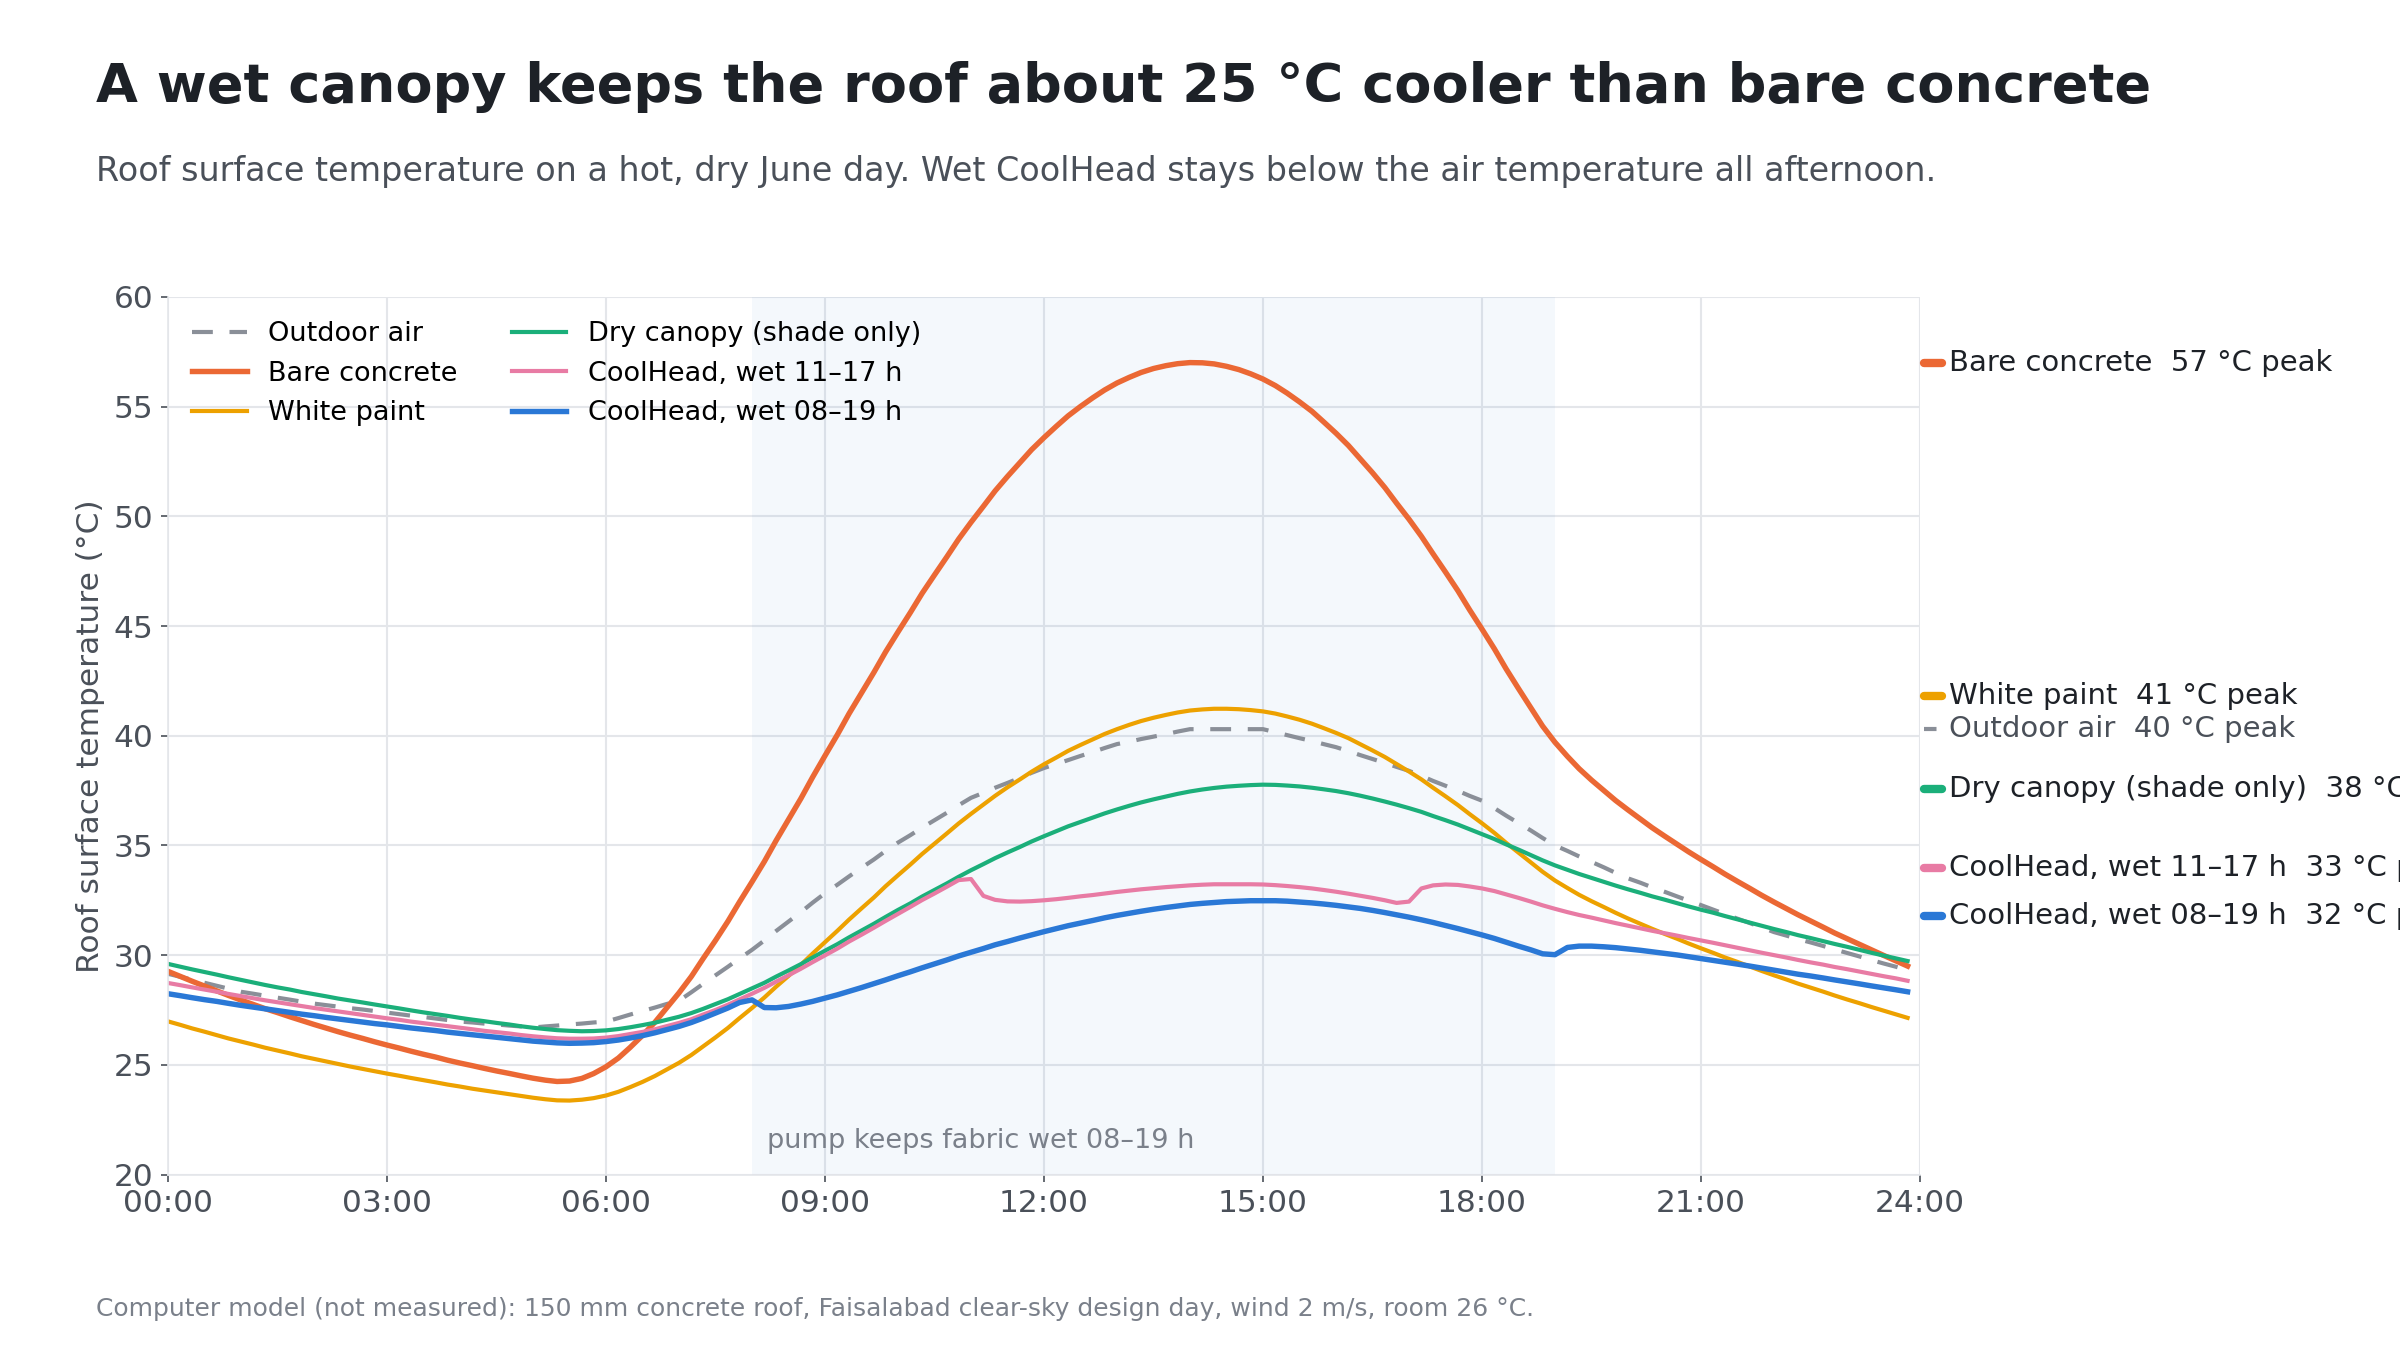

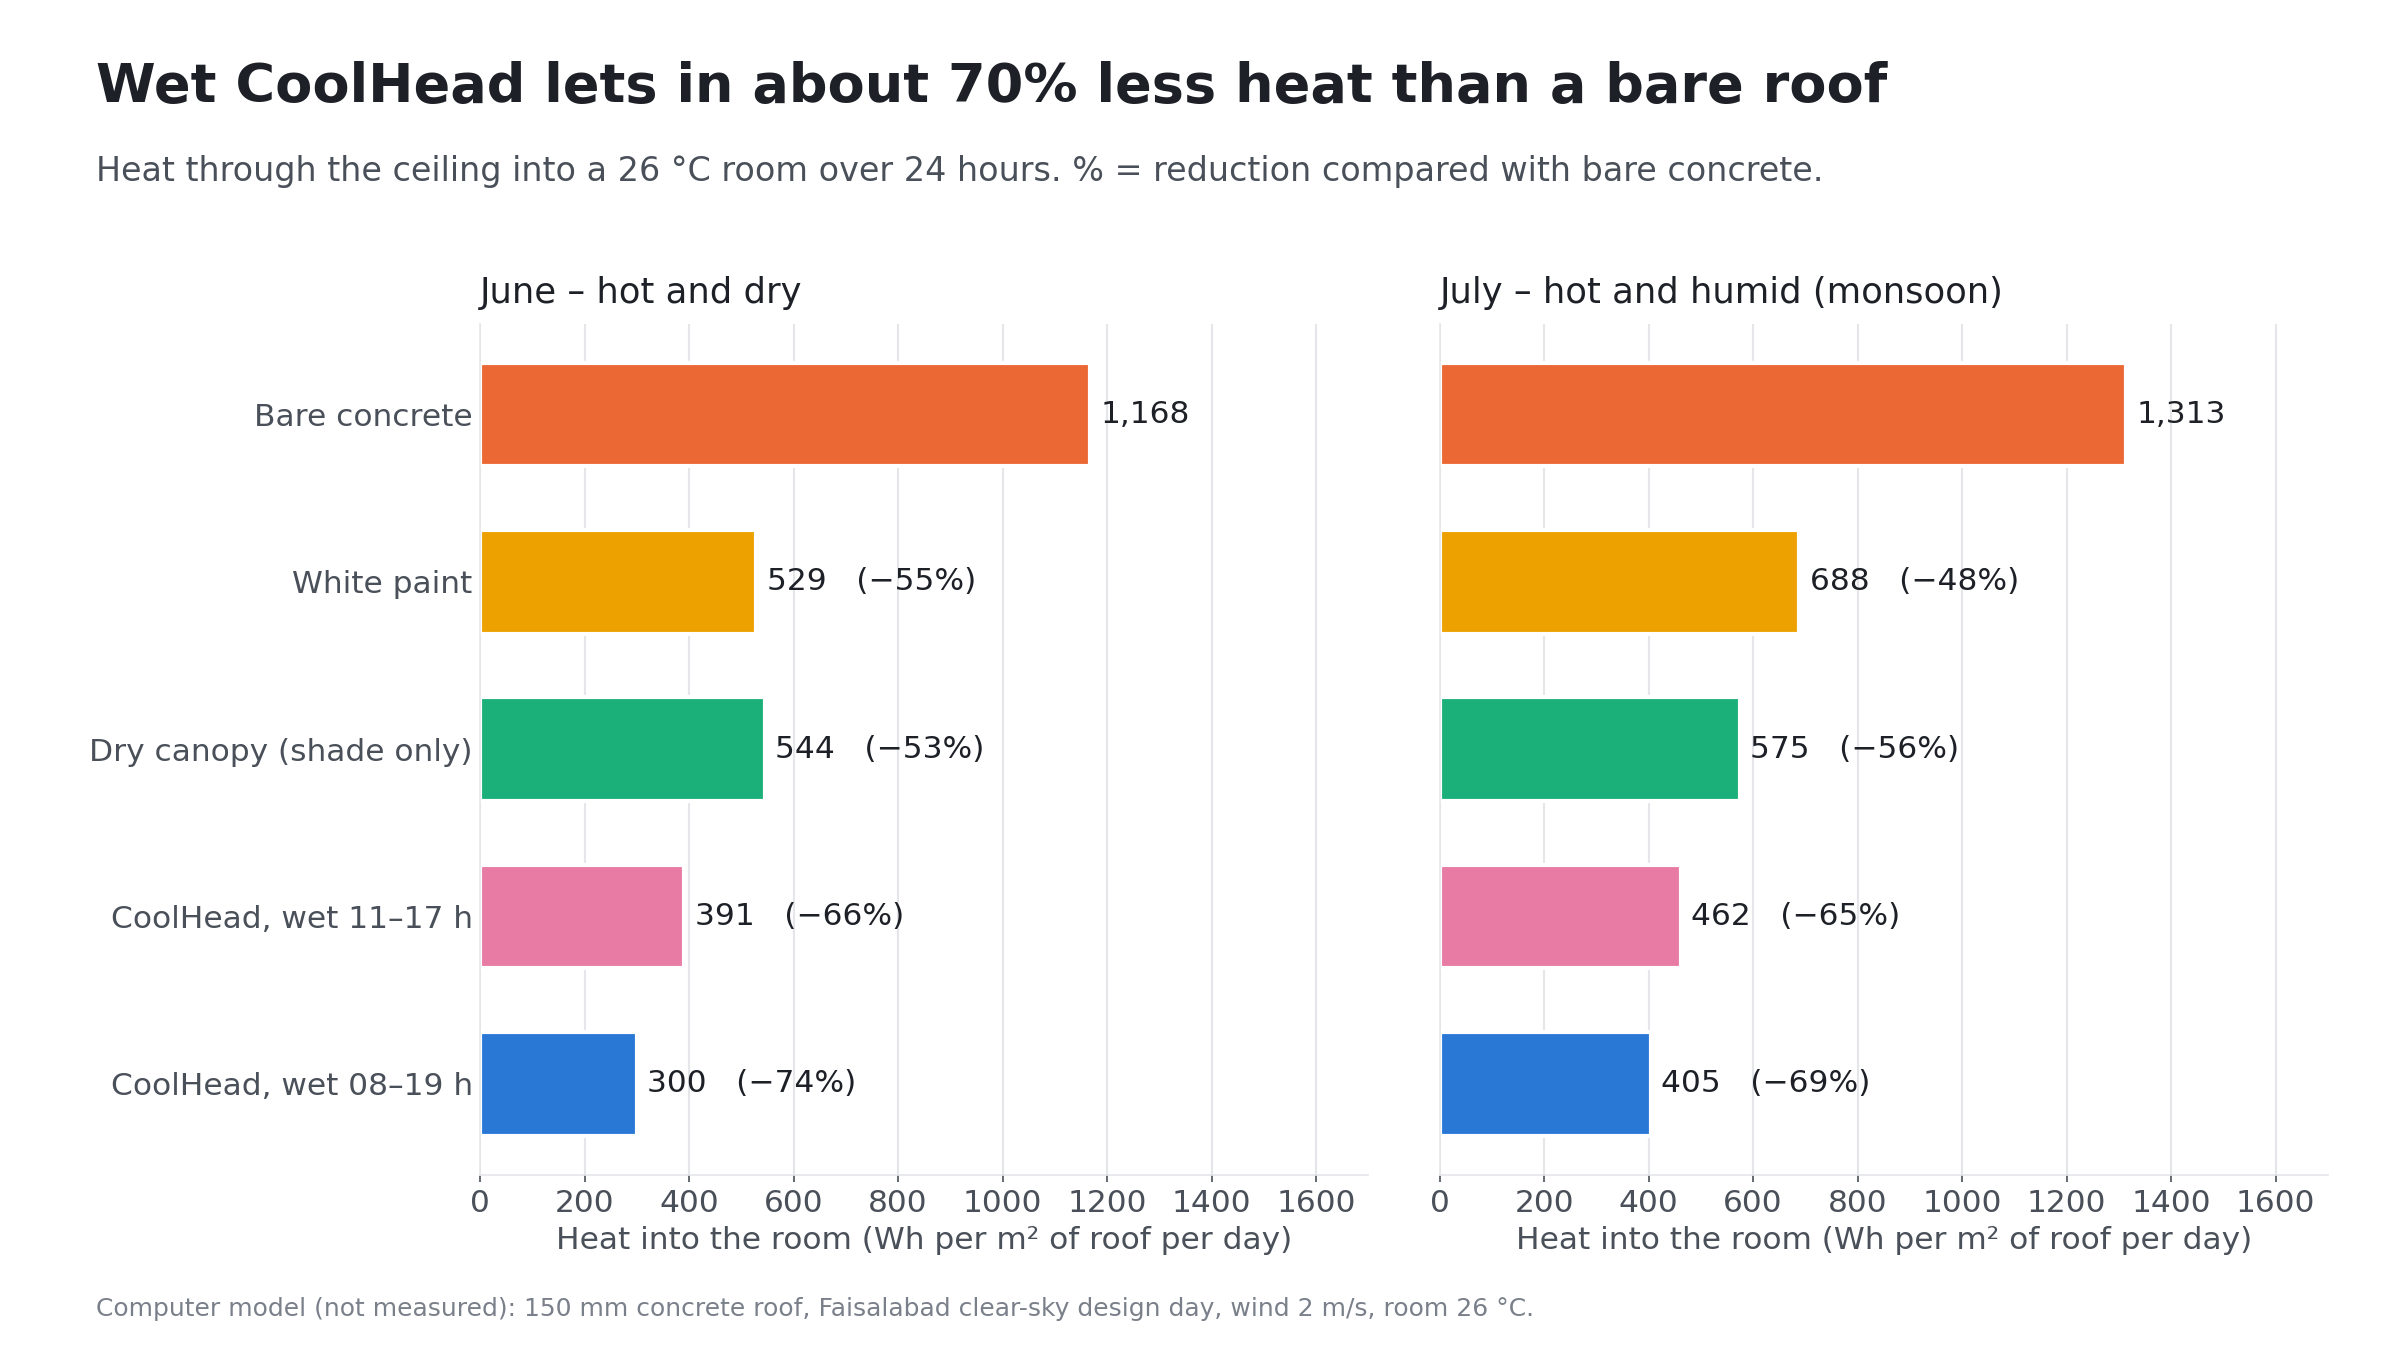

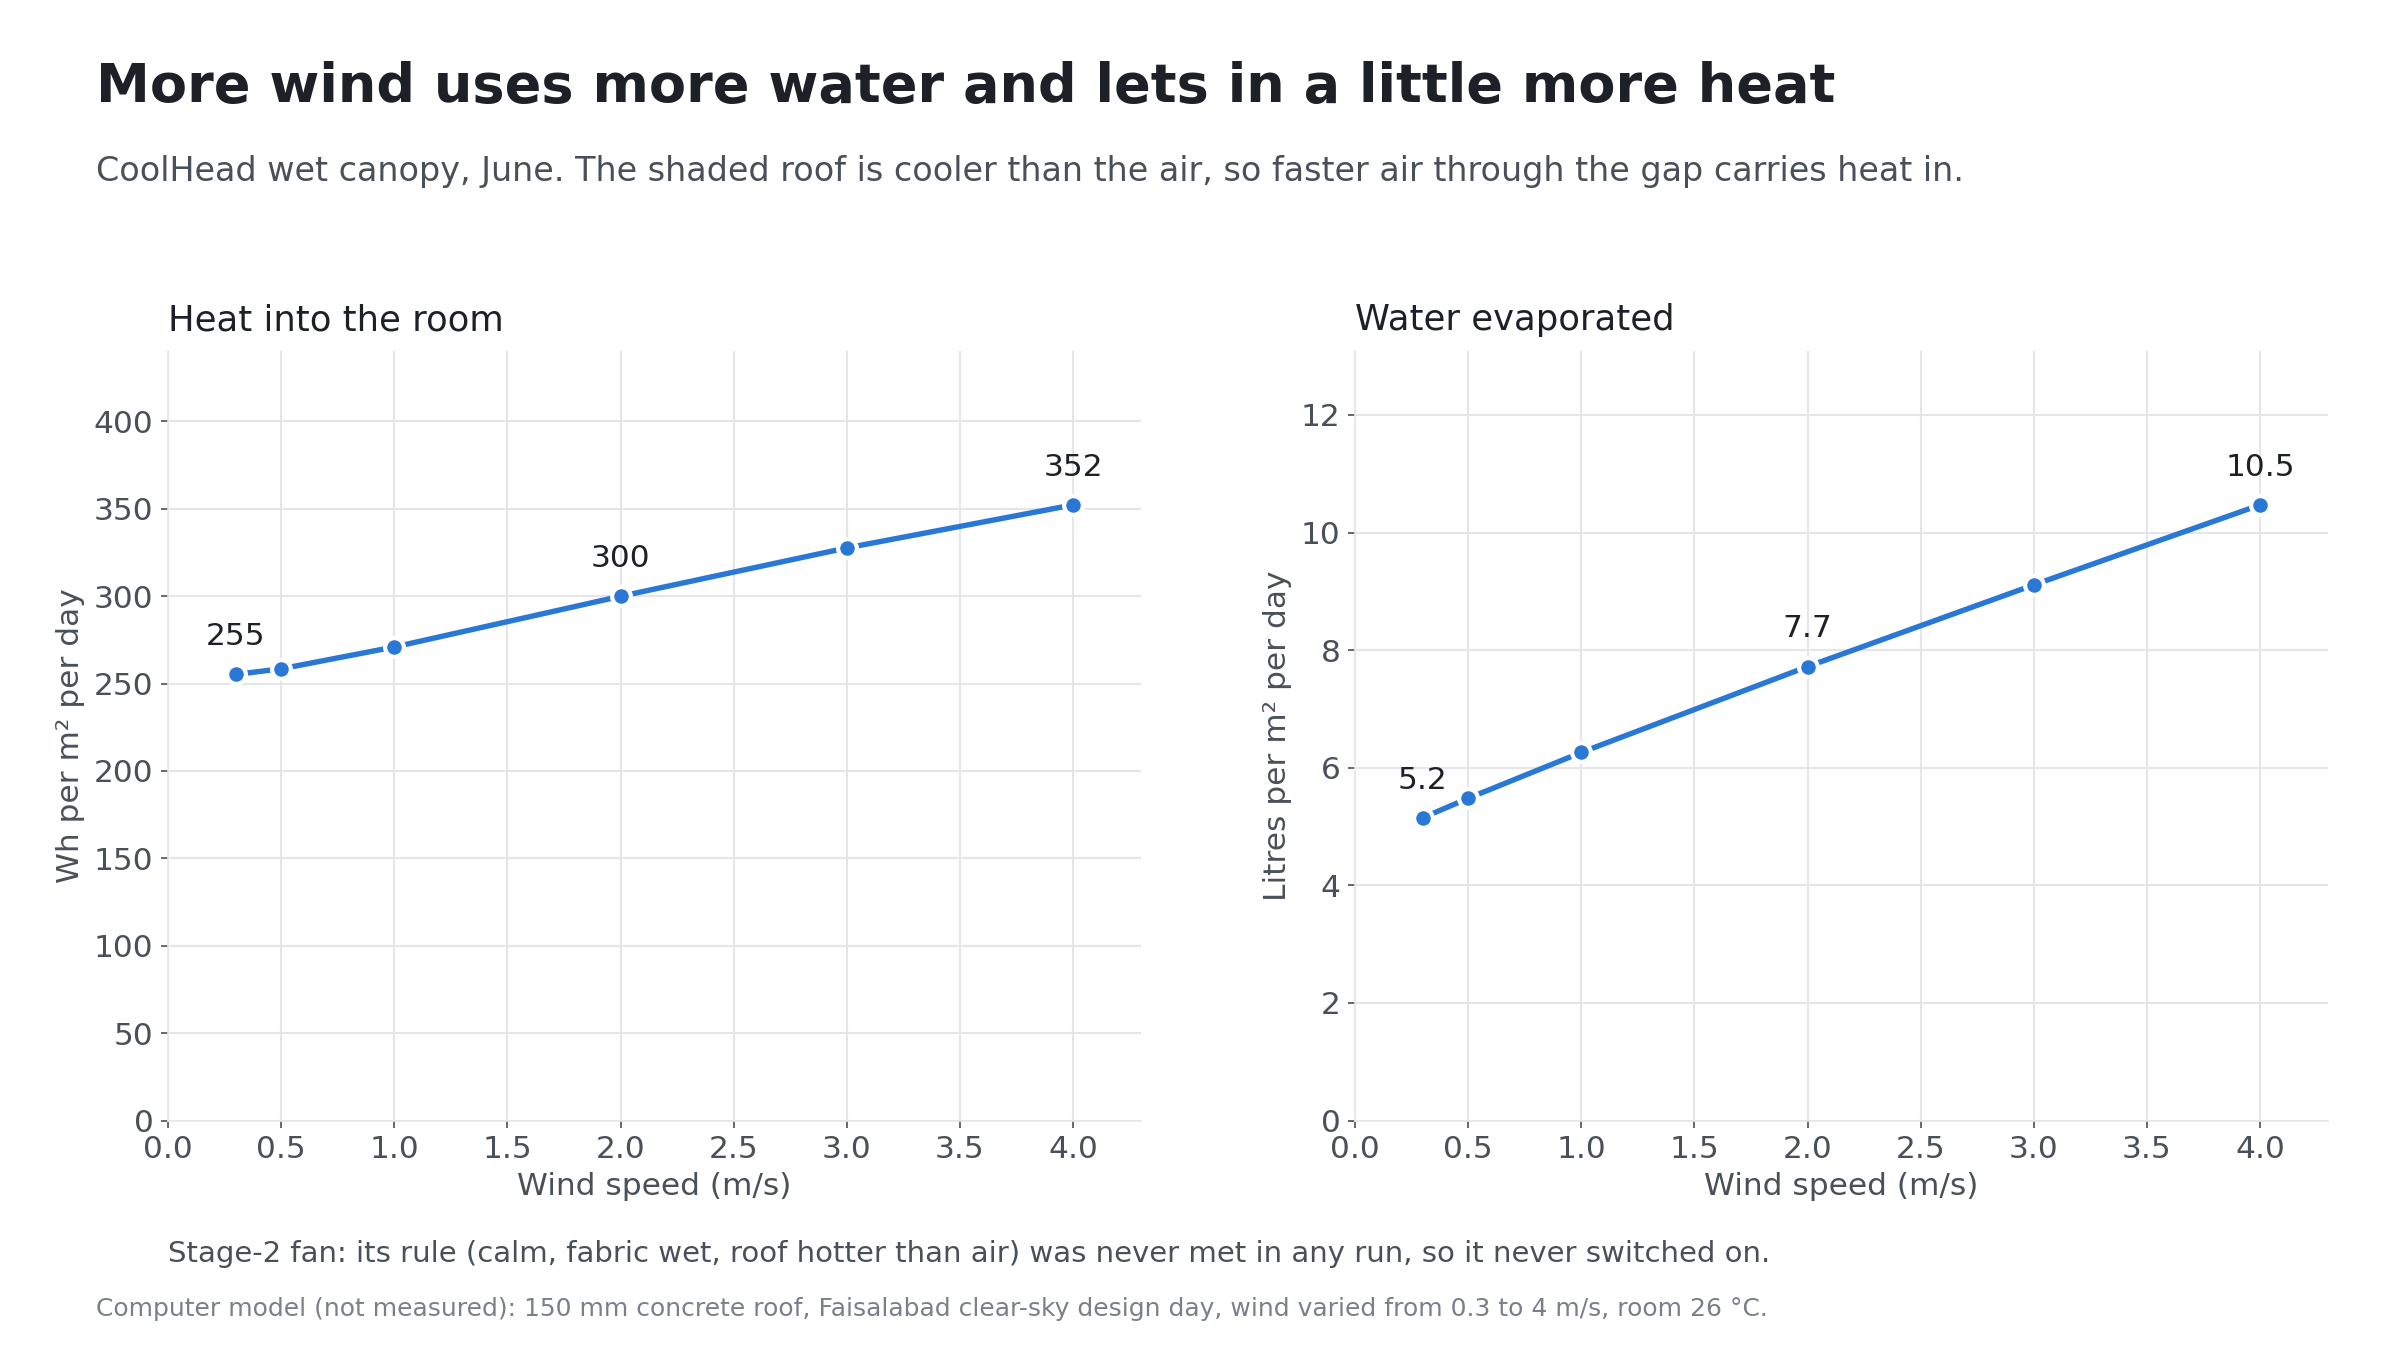

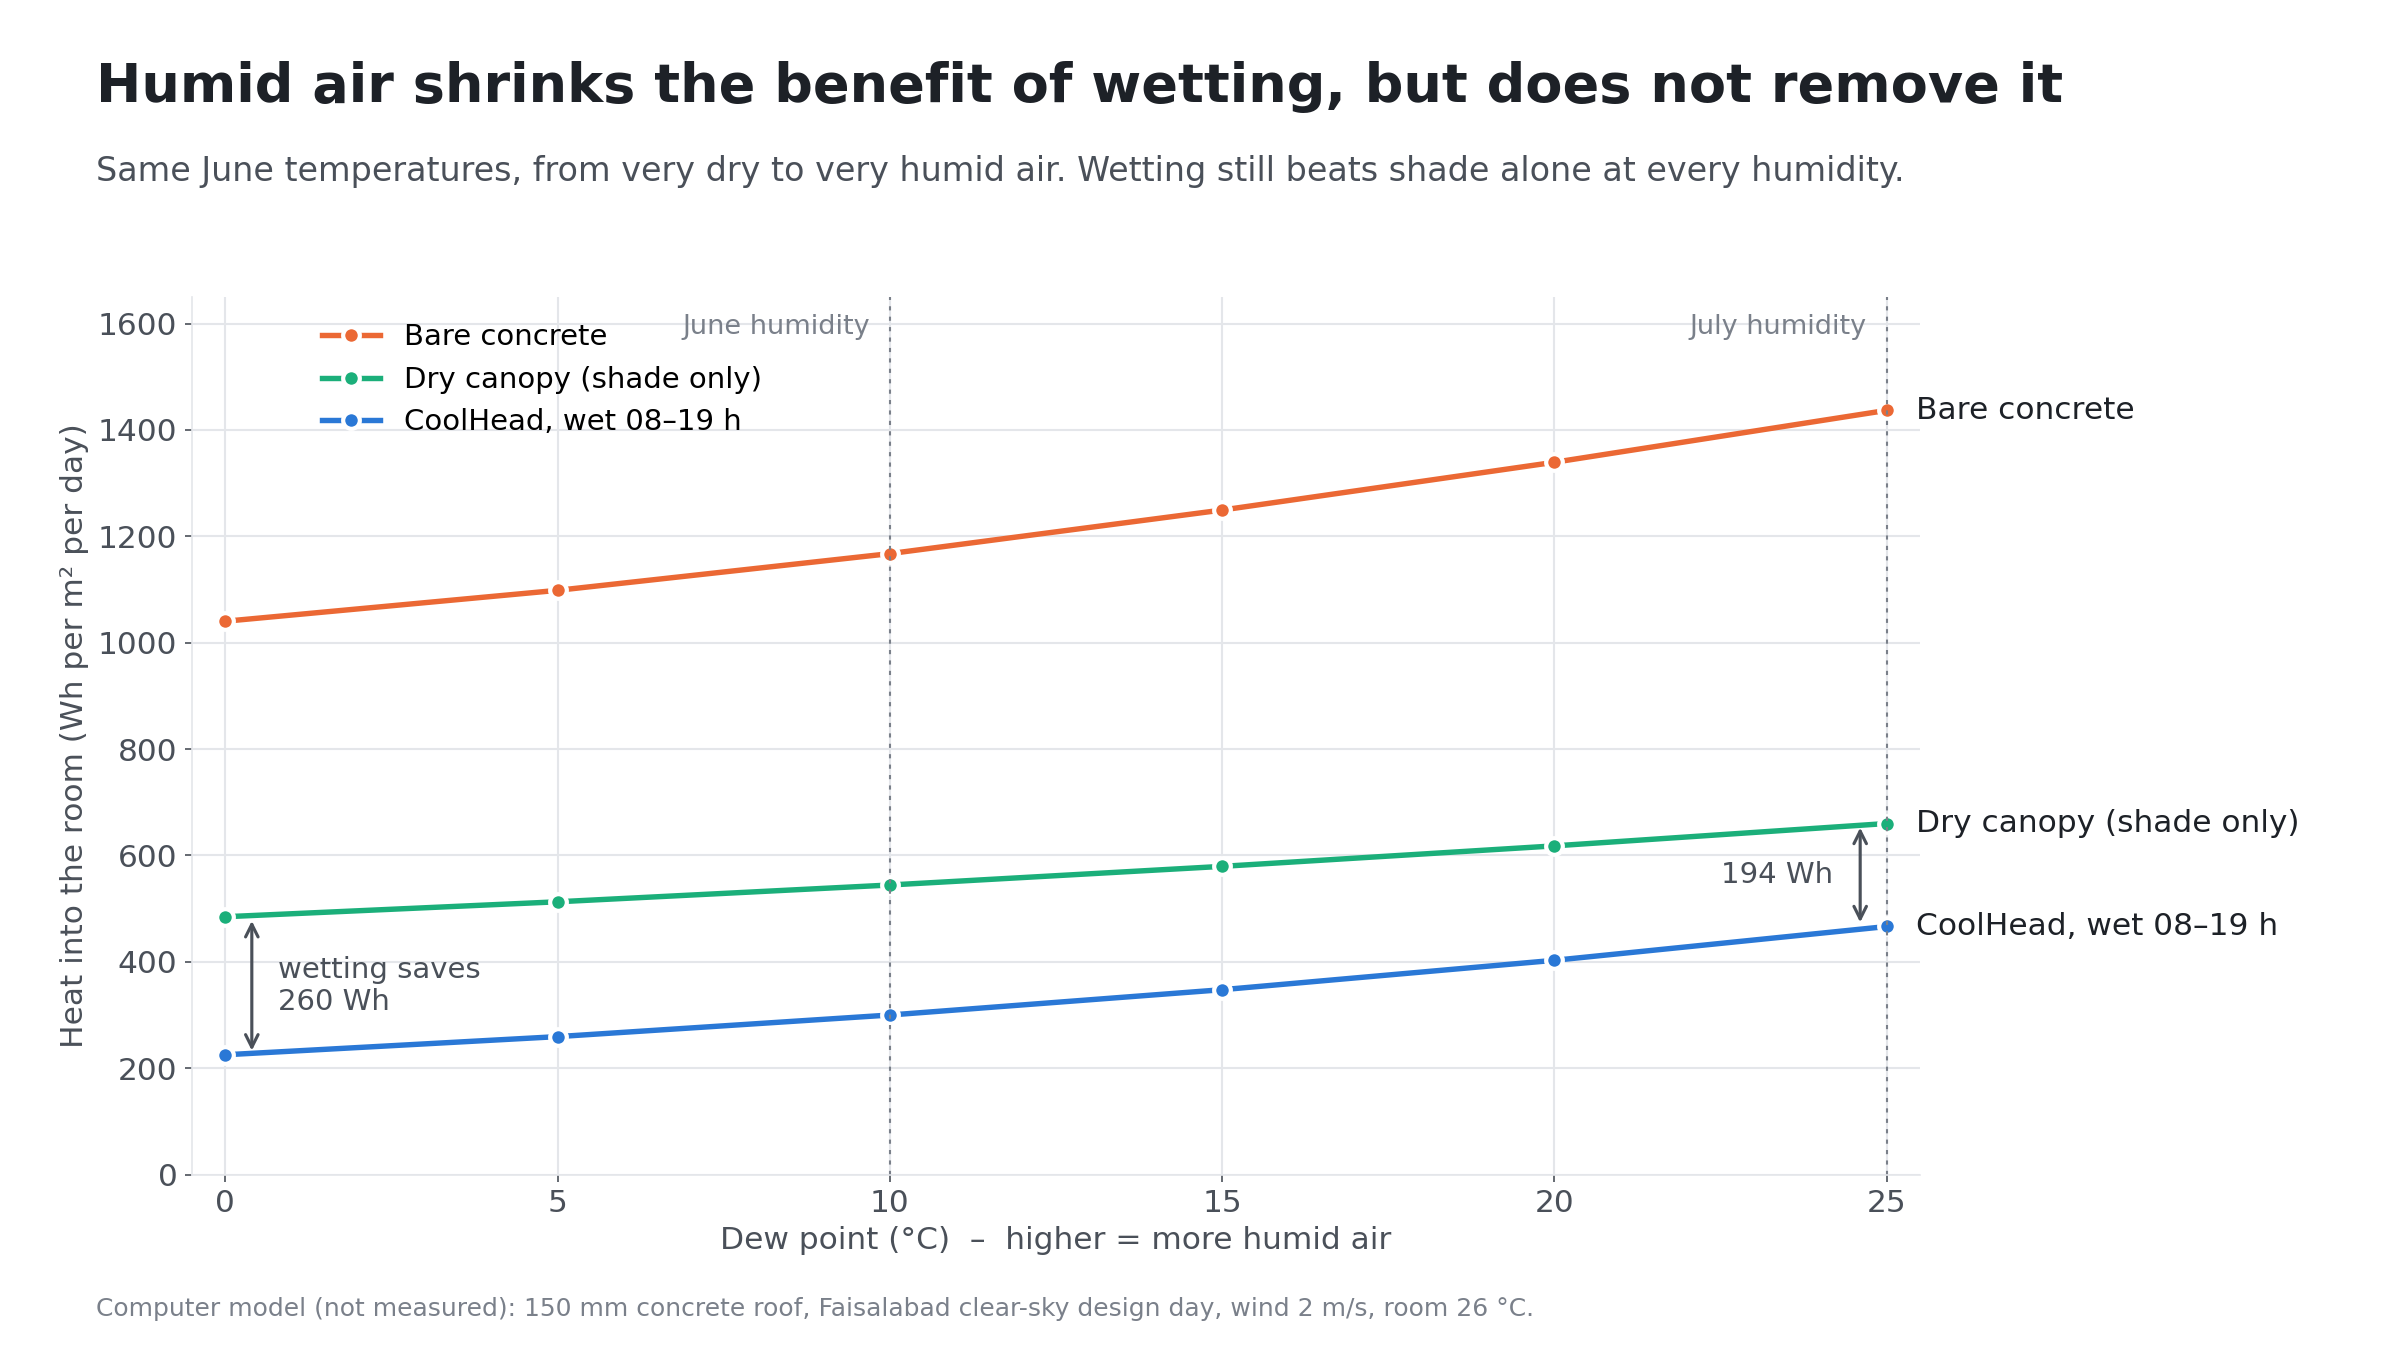

In [9]:
from IPython.display import Image, display
for f in sorted(os.listdir('charts')):
    display(Image(f'charts/{f}'))